# Bribri TTS: MCD and MOS Analysis

COSC 72 Final Project — Spring 2026

Ikenna Nwafor & Zachary Shah

Ikenna.27@dartmouth.edu

Zachary.s.shah.27@dartmouth.edu

Computes objective evaluation (Mel Cepstral Distortion against human reference) for the four TTS systems, and analyzes the subjective MOS results returned by our native-speaker rater. Produces a summary table and four publication-ready figures used in the writeup and presentation.

## Inputs
- `outputs/final_eval_set/` on Drive: 100 audio files (5 conditions × 20 sentences)
- `bribri-tts-respuestas.csv`: MOS scores from Franklin (native Bribri speaker), one row per audio file
- `csv/bribri-wav2vec2-{train,valid,test}.csv`: dataset manifests for the corpus stats

## Outputs
- Console summary of corpus durations (train/valid/test split sizes in minutes)
- MCD per condition (mean ± std), printed and used in the MCD-vs-MOS plot
- MOS summary table (mean, std, N) per condition
- Four PNG figures: `mos_bar.png`, `mcd_vs_mos.png`, `mos_distribution.png`, `mos_heatmap.png`

## Runtime
Colab T4 or any CPU runtime works. Total run time ~2 minutes (most of it pymcd's DTW alignment over 80 file pairs).

### 0. Setup

In [1]:
# 0.1 — Mount Drive and define paths
from google.colab import drive
drive.mount('/content/drive')

import os, pandas as pd, numpy as np, soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns

# adjust to what you defined as your drive root in previous scripts
DRIVE_ROOT = '/content/drive/MyDrive/Junior/cosc72'
CSV_DIR    = f'{DRIVE_ROOT}/csv'
WAV_DIR    = f'{DRIVE_ROOT}/wav'
FINAL_DIR  = f'{DRIVE_ROOT}/outputs/final_eval_set'


Mounted at /content/drive


### 1. Corpus duration

Measures the actual audio duration of each split. Reports clip count, total minutes, and mean clip length per split. Used in the writeup methodology section to give an exact figure for total training data.

In [2]:
# 1.1 — Compute total audio duration per split
total = {}
bad = []
for split in ['train', 'valid', 'test']:
    df = pd.read_csv(f'{CSV_DIR}/bribri-wav2vec2-{split}.csv')
    durations = []
    for p in df['path']:
        wav_path = f'{WAV_DIR}/{os.path.basename(p)}'
        try:
            durations.append(sf.info(wav_path).duration)
        except Exception:
            bad.append(wav_path)
    total[split] = sum(durations)
    mean_clip = sum(durations) / max(len(durations), 1)
    print(f"{split:6s}: {len(durations):4d} clips, {total[split]/60:.2f} min, mean clip {mean_clip:.2f}s")

grand = sum(total.values())
print(f"\nTotal: {grand/60:.2f} min ({grand:.1f} sec)")
print(f"Training only: {total['train']/60:.2f} min")
print(f"Skipped {len(bad)} broken files")


train :  449 clips, 19.29 min, mean clip 2.58s
valid :   56 clips, 2.60 min, mean clip 2.79s
test  :   56 clips, 2.86 min, mean clip 3.06s

Total: 24.76 min (1485.4 sec)
Training only: 19.29 min
Skipped 0 broken files


### 2. MCD (Mel Cepstral Distortion)

Computes the spectral distance between each synthesized sample and the corresponding human reference recording, averaged over 20 sentences per condition. Uses Dynamic Time Warping to align timing differences before frame-by-frame comparison. Lower MCD = closer to human spectrogram. Values below 8 dB are conventionally considered "publishable quality" in the TTS literature.

In [3]:
# 2.1 — Install pymcd
!pip install -q pymcd


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.0/261.0 kB 8.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.9/461.9 kB 29.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 14.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [4]:
# 2.2 — Compute MCD per condition
from pymcd.mcd import Calculate_MCD
mcd_calculator = Calculate_MCD(MCD_mode="dtw")

CONDITIONS = ['CJP_Finetuned', 'SPA_Finetuned', 'SPA_Baseline', 'Spark_TTS']
MCD = {}
for cond in CONDITIONS:
    scores = []
    for i in range(20):
        ref = f'{FINAL_DIR}/Human_{i:02d}.wav'
        syn = f'{FINAL_DIR}/{cond}_{i:02d}.wav'
        scores.append(mcd_calculator.calculate_mcd(ref, syn))
    MCD[cond] = (float(np.mean(scores)), float(np.std(scores)))
    print(f"{cond}: {MCD[cond][0]:.2f} ± {MCD[cond][1]:.2f} dB")

MCD['Human'] = (None, None)  # placeholder for plotting


CJP_Finetuned: 3.06 ± 1.13 dB
SPA_Finetuned: 3.45 ± 1.42 dB
SPA_Baseline: 7.18 ± 1.67 dB
Spark_TTS: 6.44 ± 1.80 dB


### 3. MOS (Mean Opinion Score) analysis

Loads the native-speaker rater's CSV (`bribri-tts-respuestas.csv`), computes the MOS summary per condition, and pairs it with the MCD values from section 2 for the divergence plot.

In [5]:
# 3.1 — Read the MOS results (drag bribri-tts-respuestas.csv into Colab's file panel first)
df = pd.read_csv('bribri-tts-respuestas.csv')
print(f"Loaded {len(df)} rows")
print(df.head())

Loaded 100 rows
  Evaluador               Muestra                  Texto  Calificacion  \
0  franklin  CJP_Finetuned_00.wav           kàl wö iene̠             3   
1  franklin  CJP_Finetuned_01.wav      e'r be' kutàiene̠             3   
2  franklin  CJP_Finetuned_02.wav      tsá̠li̠ ta̠ é̠ma̠             3   
3  franklin  CJP_Finetuned_03.wav  e' kë̀ bua'ne̠i̠a̠ne̠             2   
4  franklin  CJP_Finetuned_04.wav        e's ie i wà dör             2   

                            Descripcion             Fecha         system  
0  Aceptable — parcialmente inteligible  2026-06-02 13:42  CJP_Finetuned  
1  Aceptable — parcialmente inteligible  2026-06-02 13:47  CJP_Finetuned  
2  Aceptable — parcialmente inteligible  2026-06-02 13:52  CJP_Finetuned  
3      Pobre — dificultad para entender  2026-06-02 13:45  CJP_Finetuned  
4      Pobre — dificultad para entender  2026-06-02 13:44  CJP_Finetuned  


In [6]:
# 3.2 — Compute MOS summary and combine with MCD
summary = df.groupby('system')['Calificacion'].agg(['mean', 'std', 'count']).round(2)
summary.columns = ['MOS', 'StdMOS', 'N']
summary['MCD'] = summary.index.map(lambda s: MCD[s][0] if s in MCD else None)
summary['StdMCD'] = summary.index.map(lambda s: MCD[s][1] if s in MCD else None)
print(summary.sort_values('MOS', ascending=False))


                MOS  StdMOS   N       MCD    StdMCD
system                                             
Human          3.85    0.37  20       NaN       NaN
Spark_TTS      2.75    0.85  20  6.435082  1.803340
CJP_Finetuned  2.55    0.76  20  3.060048  1.131765
SPA_Baseline   2.10    0.72  20  7.179684  1.674970
SPA_Finetuned  2.10    0.72  20  3.451367  1.420497


### 4. Visualizations

Four figures used in the writeup and slides:
1. Bar chart of MOS per condition with error bars (headline result)
2. Scatter of MCD vs MOS showing the divergence between objective and subjective metrics
3. Violin plot of MOS distribution per system (shows variance across sentences)
4. Per-sentence heatmap (shows which specific sentences each system handled well or poorly)

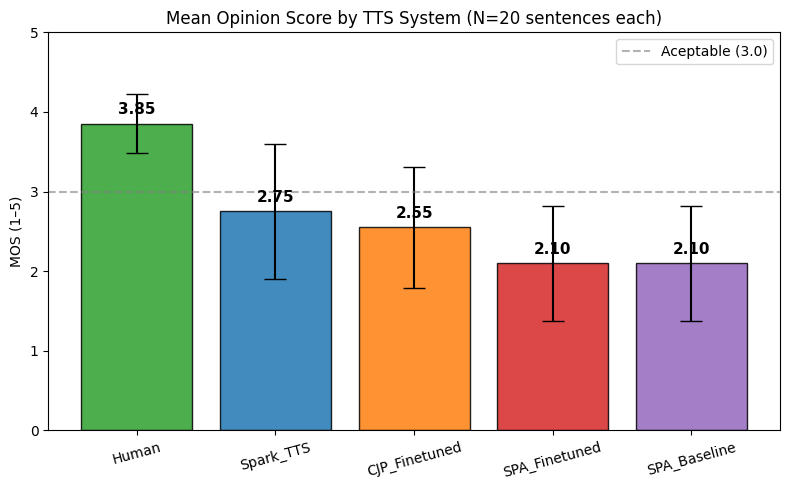

In [7]:
# 4.1 — Plot 1: MOS bar chart with error bars
order = ['Human', 'Spark_TTS', 'CJP_Finetuned', 'SPA_Finetuned', 'SPA_Baseline']
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728', '#9467bd']
means = [summary.loc[s, 'MOS'] for s in order]
stds  = [summary.loc[s, 'StdMOS'] for s in order]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order, means, yerr=stds, capsize=8, color=colors,
              edgecolor='black', alpha=0.85)
ax.axhline(3, color='gray', linestyle='--', alpha=0.6, label='Aceptable (3.0)')
ax.set_ylabel('MOS (1–5)')
ax.set_ylim(0, 5)
ax.set_title('Mean Opinion Score by TTS System (N=20 sentences each)')
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.12, f'{m:.2f}',
            ha='center', fontsize=11, fontweight='bold')
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('mos_bar.png', dpi=200, bbox_inches='tight')
plt.show()


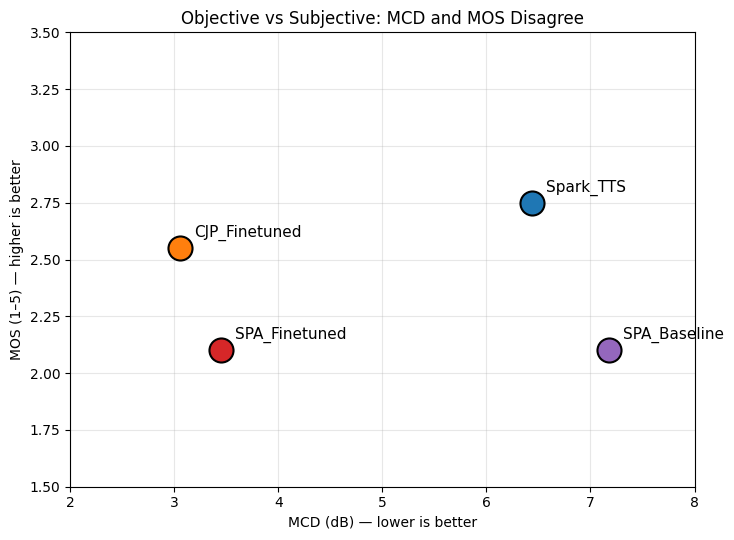

In [8]:
# 4.2 — Plot 2: MCD vs MOS scatter (the methodological finding)
m = summary.dropna(subset=['MCD'])

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for sys_ in m.index:
    ci = colors[order.index(sys_)]
    ax.scatter(m.loc[sys_, 'MCD'], m.loc[sys_, 'MOS'], s=300,
               color=ci, edgecolor='black', linewidth=1.5, zorder=3)
    ax.annotate(sys_, (m.loc[sys_, 'MCD'], m.loc[sys_, 'MOS']),
                xytext=(10, 8), textcoords='offset points', fontsize=11)
ax.set_xlabel('MCD (dB) — lower is better')
ax.set_ylabel('MOS (1–5) — higher is better')
ax.set_title('Objective vs Subjective: MCD and MOS Disagree')
ax.set_xlim(2, 8)
ax.set_ylim(1.5, 3.5)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('mcd_vs_mos.png', dpi=200, bbox_inches='tight')
plt.show()


/tmp/ipykernel_312/3071825845.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_o, x='system', y='Calificacion', inner='quart',


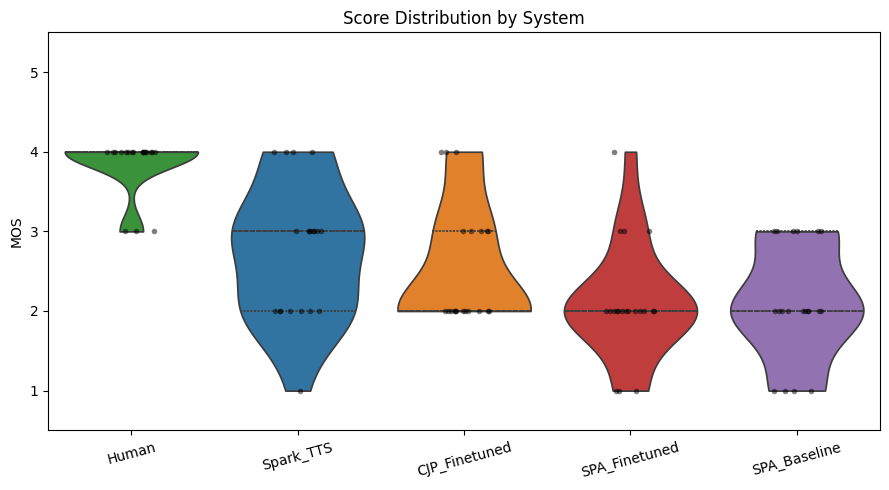

In [9]:
# 4.3 — Plot 3: Score distribution per system
df_o = df[df['system'].isin(order)].copy()
df_o['system'] = pd.Categorical(df_o['system'], categories=order, ordered=True)

fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=df_o, x='system', y='Calificacion', inner='quart',
               order=order, palette=colors, ax=ax, cut=0)
sns.stripplot(data=df_o, x='system', y='Calificacion', color='black',
              alpha=0.5, jitter=0.15, order=order, ax=ax, size=4)
ax.set_ylim(0.5, 5.5)
ax.set_ylabel('MOS')
ax.set_xlabel('')
ax.set_title('Score Distribution by System')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('mos_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


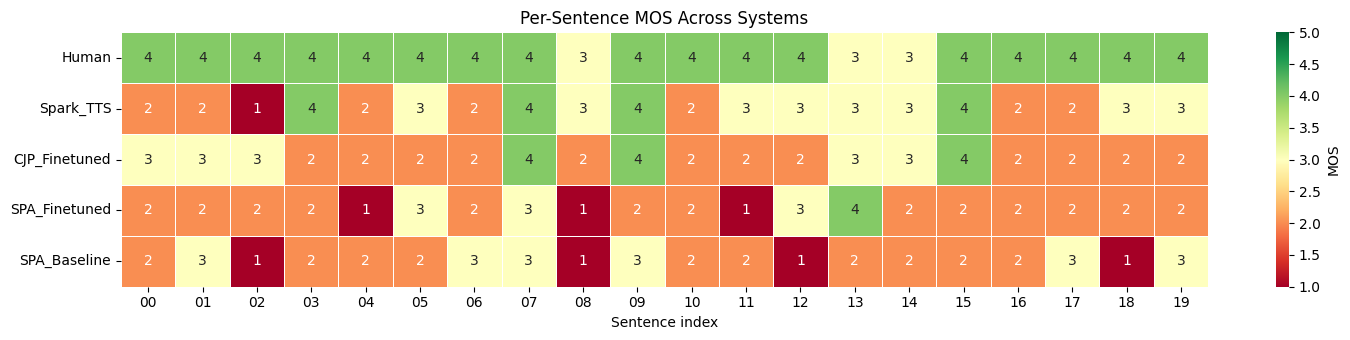

In [10]:
# 4.4 — Plot 4: Per-sentence heatmap
mat = np.full((len(order), 20), np.nan)
for i, s in enumerate(order):
    for j in range(20):
        row = df[(df['system'] == s) & df['Muestra'].str.contains(f'_{j:02d}\\.wav', regex=True)]
        if len(row):
            mat[i, j] = row['Calificacion'].iloc[0]

fig, ax = plt.subplots(figsize=(15, 3.5))
sns.heatmap(mat, annot=True, fmt='.0f', cmap='RdYlGn',
            xticklabels=[f'{i:02d}' for i in range(20)],
            yticklabels=order, vmin=1, vmax=5,
            cbar_kws={'label': 'MOS'}, ax=ax, linewidths=0.5)
ax.set_xlabel('Sentence index')
ax.set_title('Per-Sentence MOS Across Systems')
plt.tight_layout()
plt.savefig('mos_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()


In [ ]:
# 4.5 — Download all figures
from google.colab import files
for fn in ['mos_bar.png', 'mcd_vs_mos.png', 'mos_distribution.png', 'mos_heatmap.png']:
    files.download(fn)
